# Josué Uriel Martínez Ruíz

Colab: https://colab.research.google.com/drive/1T_P-eiqMwnnAyq45p-eYanGBuoSlW3Lw?usp=sharing

GitHub: https://github.com/josue-mtz/Deeplearning-para-vision-por-computadoras

#Deep Learning para visión de computadoras
##Lab 2.3 Redes recurrentes en visión

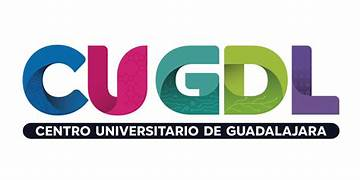

•	Video como secuencia de frames
•	Arquitectura CNN-LSTM para procesamiento temporal
•	Aplicación: clasificación de acciones en video
•	Comparativa: CNN estática versus CNN-LSTM


## Librerías



In [1]:
import time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 3
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

ACCIONES = ["derecha", "izquierda", "arriba", "abajo", "giro horario", "giro antihorario"]
N_CLASES = len(ACCIONES)
TAM, T = 32, 16        # frames de 32 x 32 píxeles, 16 frames por video

Dispositivo: cuda · Tesla T4
torch 2.11.0+cu130


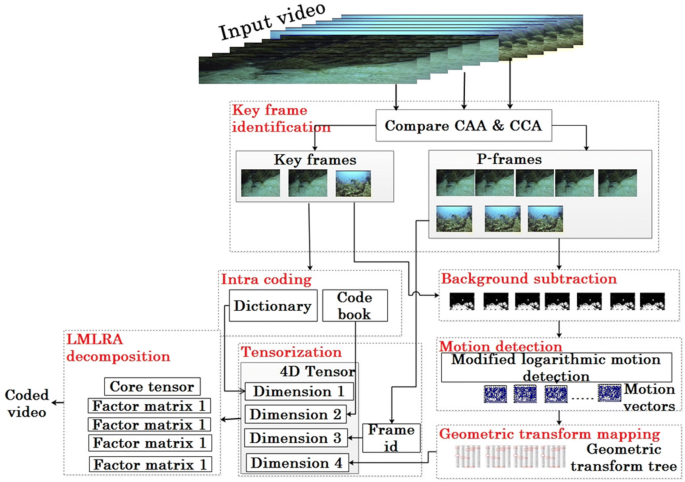

https://link.springer.com/article/10.1007/s11277-019-06704-4

---
# PARTE A
Un video es un tensor con una dimensión más

Una imagen en escala de grises es un tensor $(1, H, W)$. Un video de $T$ frames es $(T, 1, H, W)$, y un lote de videos es $(B, T, 1, H, W)$. Las seis acciones son:

| Acciones | Qué ocurre | Qué distingue una de otra |
|---|---|---|
| `derecha`, `izquierda`, `arriba`, `abajo` | La pelota cruza la imagen en línea recta | **Sentido** del desplazamiento |
| `giro horario`, `giro antihorario` | La pelota recorre una circunferencia | **Sentido** de giro |

Entrenamiento: (1200, 16, 1, 32, 32) = (videos, frames, canales, alto, ancho)
Validación   : (300, 16, 1, 32, 32)
Tamaño en memoria del entrenamiento: 79 MB


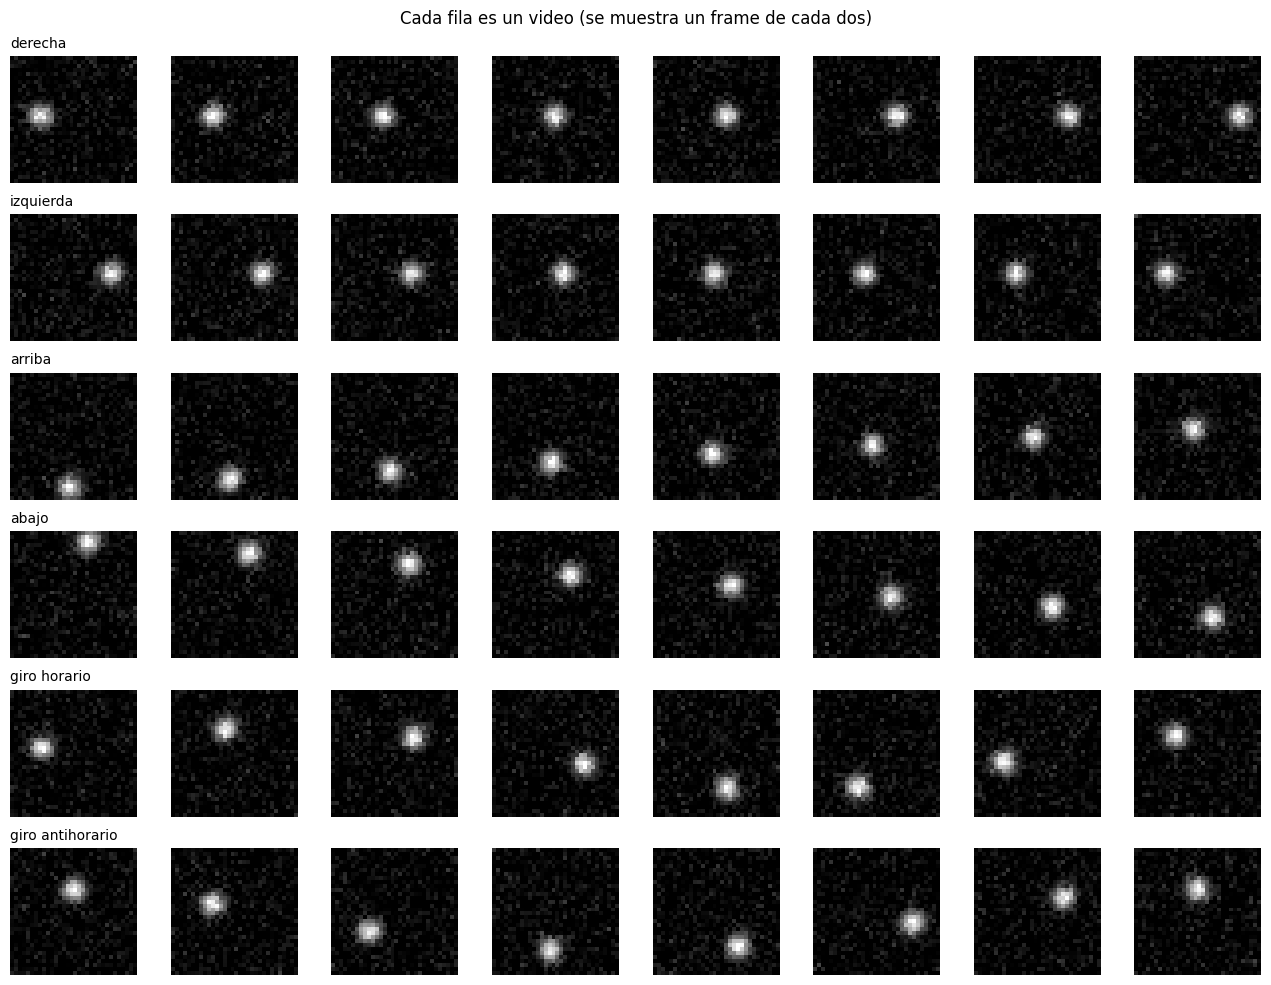

In [2]:
def generar_video(rng, clase, T=T, tam=TAM):
    yy, xx = np.mgrid[0:tam, 0:tam].astype(np.float32)
    v = rng.uniform(1.0, 1.4)
    jit = rng.uniform(-4, 4, 2)
    t = np.arange(T)
    c = tam / 2
    if clase < 4:
        dx, dy = [(1, 0), (-1, 0), (0, -1), (0, 1)][clase]
        cx = c + jit[0] + dx * v * (t - T / 2); cy = c + jit[1] + dy * v * (t - T / 2)
    else:
        sentido = 1 if clase == 4 else -1
        fase = rng.uniform(0, 2 * np.pi); w = rng.uniform(0.35, 0.5)   # radianes por frame
        cx = c + jit[0] * 0.5 + 8 * np.cos(fase + sentido * w * t); cy = c + jit[1] * 0.5 + 8 * np.sin(fase + sentido * w * t)
    frames = np.exp(-((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2) / (2 * 2.0 ** 2))
    frames = frames + rng.normal(0, 0.08, frames.shape)
    return np.clip(frames, 0, 1).astype(np.float32)[:, None]      # (T, 1, H, W)

def generar_dataset(n_por_clase, semilla):
    rng = np.random.default_rng(semilla)
    X, Y = [], []
    for clase in range(N_CLASES):
        for _ in range(n_por_clase):
            X.append(generar_video(rng, clase)); Y.append(clase)
    X, Y = torch.tensor(np.stack(X)), torch.tensor(Y)
    p = torch.randperm(len(X), generator=torch.Generator().manual_seed(semilla))
    return X[p], Y[p]

X_ent, Y_ent = generar_dataset(200, semilla=1)
X_val, Y_val = generar_dataset(50, semilla=2)
print("Entrenamiento:", tuple(X_ent.shape), "= (videos, frames, canales, alto, ancho)")
print("Validación   :", tuple(X_val.shape))
print(f"Tamaño en memoria del entrenamiento: {X_ent.numel()*4/1e6:.0f} MB")

fig, ax = plt.subplots(6, 8, figsize=(13, 10))
for c in range(N_CLASES):
    i = int((Y_ent == c).nonzero()[0])
    for j, t in enumerate(range(0, T, 2)):
        ax[c, j].imshow(X_ent[i, t, 0], cmap="gray", vmin=0, vmax=1); ax[c, j].axis("off")
        if j == 0: ax[c, j].set_title(ACCIONES[c], loc="left", fontsize=10)
plt.suptitle("Cada fila es un video (se muestra un frame de cada dos)"); plt.tight_layout(); plt.show()

¿Qué observaste? Explica por qué, para clasificar la acción en `derecha` vs. `izquierda`, se necesita comparar **al menos dos frames**.

**El histograma del centroide X en t=8 muestra que "derecha" y "izquierda" producen distribuciones idénticas, ambas centradas en 16 (la mitad de la imagen).\
Esto ocurre porque las dos trayectorias son simétricas alrededor del centro temporal en el frame 8 la pelota está a mitad de camino en ambos casos.**

**Un frame suelto contiene solo la posición instantánea: "la pelota está en (x, y)", eso es igual para "derecha" e "izquierda" si en ambos la pelota pasa por ese punto y la dirección es una propiedad del cambio y el cambio solo aparece comparando al menos dos instantes:**

$$\text{derecha} \iff x_{t+1} - x_t > 0, \quad \text{izquierda} \iff x_{t+1} - x_t < 0$$


¿Cuántos números tiene un video de este conjunto? ¿Y un video de 10 s a 30 fps y 224×224 RGB? Calcula el tamaño en MB (float32) y comenta qué implica para el lote que cabe en la GPU.

In [17]:
# Tamaños de un video
T_ds, C, H, W = 16, 1, 32, 32
n_ds = T_ds * C * H * W
print(f"Video del dataset: {n_ds:,} números = {n_ds*4/1024:.1f} KB = {n_ds*4/1e6:.3f} MB")

T_long, C_long, H_long, W_long = 300, 3, 224, 224
n_long = T_long * C_long * H_long * W_long
print(f"Video 10s a 30fps 224×224 RGB: {n_long:,} números = {n_long*4/1e9:.2f} GB")

B = 32
print(f"Lote B={B}: {B * n_long * 4/1e9:.2f} GB (solo datos de entradas)")

Video del dataset: 16,384 números = 64.0 KB = 0.066 MB
Video 10s a 30fps 224×224 RGB: 45,158,400 números = 0.18 GB
Lote B=32: 5.78 GB (solo datos de entradas)


**En una Tesla T4 (16 GB) un batch grande apenas deja espacio para activaciones y gradientes, por eso en este laboratorio usa 32×32×16 (200 veces más barato que 224×224×300) y para producción se submuestrea T, se baja resolución o se reduce el batch.**

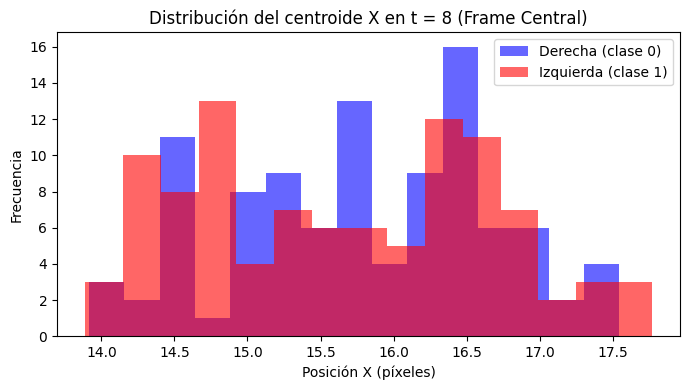

In [3]:
def centroide_x(frame):                      # frame: (1, H, W)
    f = frame[0]; xs = torch.arange(f.shape[1]).float()
    return float((f.sum(0) * xs).sum() / (f.sum() + 1e-8))

indices_der = (Y_ent == 0).nonzero().flatten()[:100]
indices_izq = (Y_ent == 1).nonzero().flatten()[:100]

cx_derecha = [centroide_x(X_ent[i, 8]) for i in indices_der]
cx_izquierda = [centroide_x(X_ent[i, 8]) for i in indices_izq]

plt.figure(figsize=(7, 4))
plt.hist(cx_derecha, bins=15, alpha=0.6, label="Derecha (clase 0)", color="blue")
plt.hist(cx_izquierda, bins=15, alpha=0.6, label="Izquierda (clase 1)", color="red")
plt.title("Distribución del centroide X en t = 8 (Frame Central)")
plt.xlabel("Posición X (píxeles)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

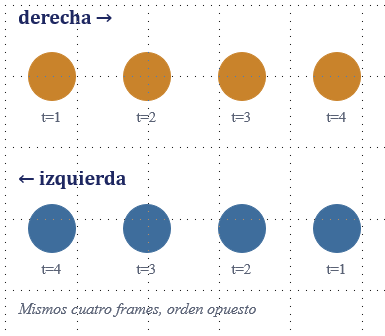

# Long-Short Term Memory (LSTM)

Las unidades de memoria a largo y corto plazo (LSTM, por sus siglas en inglés) son componentes de una red neuronal recurrente. Fueron propuestas por Hochreiter et al. en 1997. Las LSTM se diseñaron para superar el problema del «gradiente desvaneciente», que era inherente a la mayoría de las redes neuronales recurrentes de aquella época. Este problema resulta especialmente grave en secuencias largas (como el texto), ya que ralentiza considerablemente el aprendizaje o, en el peor de los casos, impide la convergencia.

Nota: Estas unidades no resuelven el problema del «gradiente explosivo»; una heurística utilizada habitualmente consiste en recortar los gradientes al alcanzar un determinado umbral.
https://colah.github.io/posts/2015-08-Understanding-LSTMs/

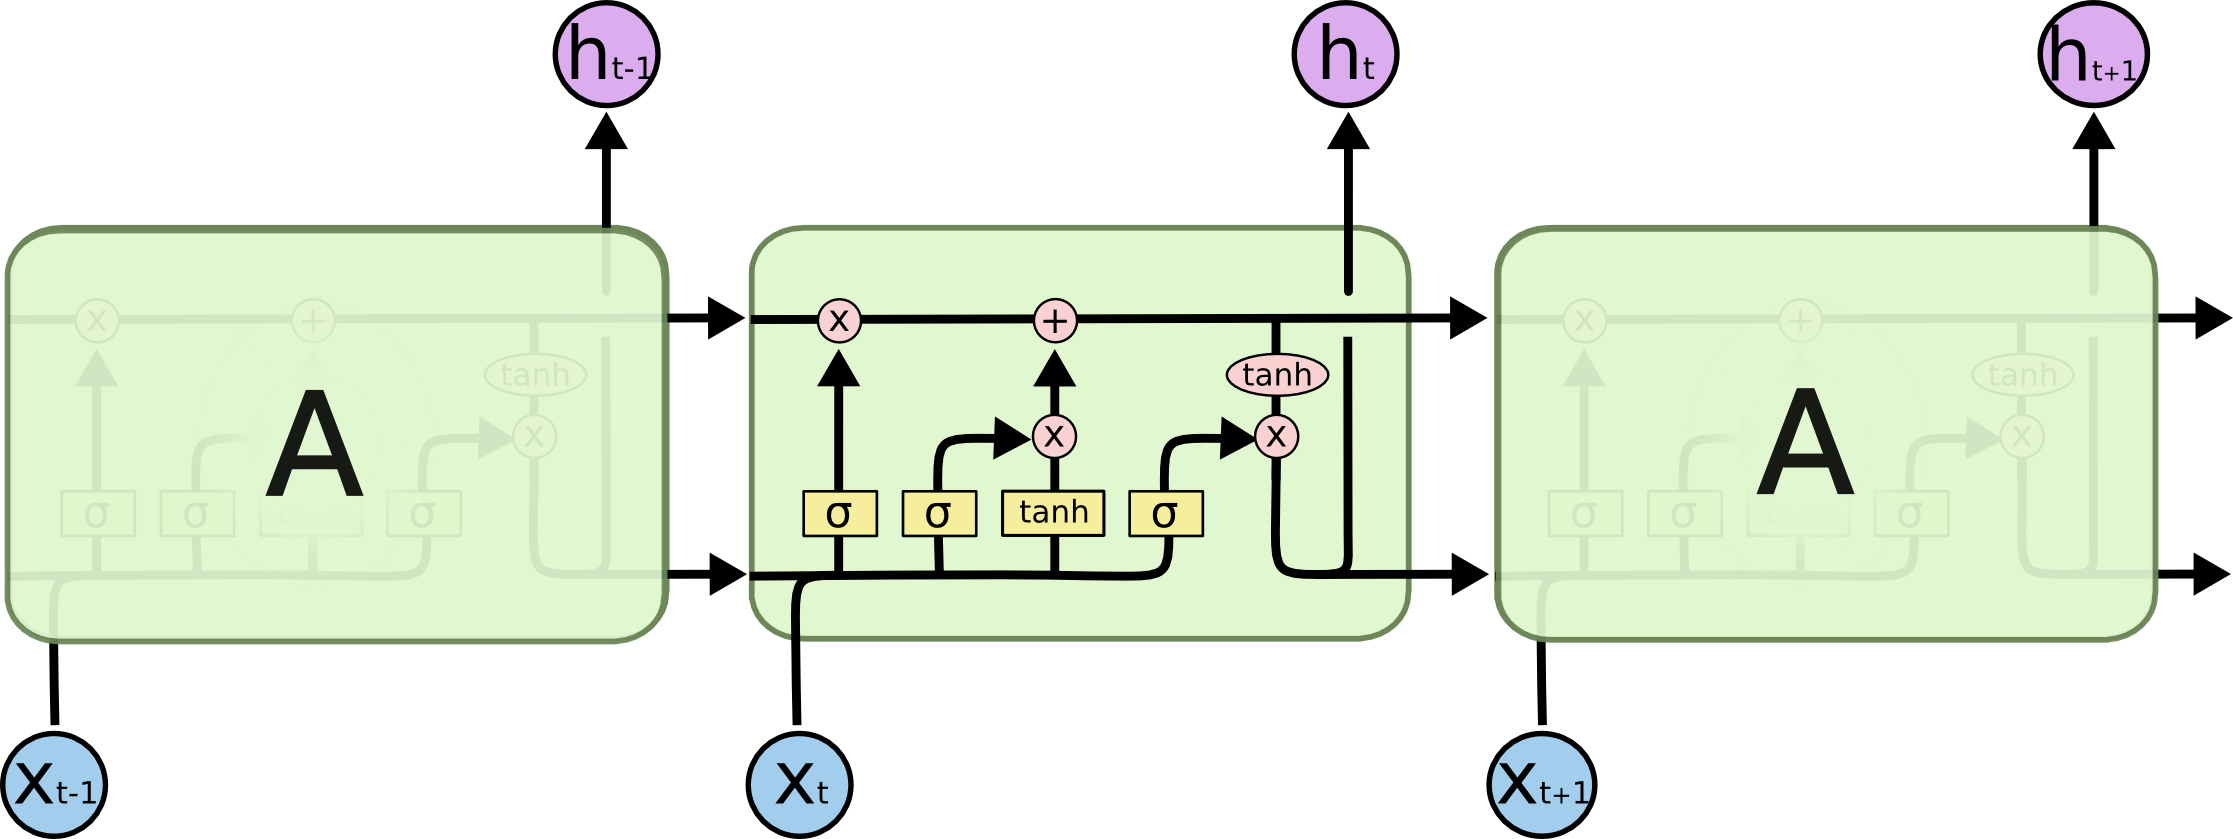

<img src="https://raw.githubusercontent.com/aaubs/ds-master/main/data/Images/LSTM_dynamic.gif" width="600">

---
# PARTE B
Dos modelos CNN-LSTM

Ambos modelos usan **el mismo extractor de características** por frame (una CNN pequeña). Lo único que cambia es qué se hace con las características de cada frame:

* **CNN estática:** clasifica **cada frame por separado**. Un video se clasifica promediando las probabilidades de sus frames (un voto, sin orden).
* **CNN-LSTM:** la CNN produce un vector por frame; una **LSTM** lee los $T$ vectores **en orden** y su último estado oculto se clasifica (añade una memoria con compuertas).

$$\mathbf{f}_t=\mathrm{CNN}(\mathbf{x}_t)\qquad (\mathbf{h}_t,\mathbf{c}_t)=\mathrm{LSTM}(\mathbf{f}_t,\mathbf{h}_{t-1},\mathbf{c}_{t-1})\qquad \hat{y}=\mathrm{softmax}(W\mathbf{h}_T)$$

In [4]:
class CodificadorCNN(nn.Module):
    """Convierte un frame (1x32x32) en un vector de características de tamaño 'dim'."""
    def __init__(self, dim=64):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),     # 16x16
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 8x8
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(2),  # 2x2
            nn.Flatten(), nn.Linear(64 * 4, dim), nn.ReLU())
    def forward(self, x): return self.f(x)

class CNNEstatica(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.cnn = CodificadorCNN(dim); self.clasif = nn.Linear(dim, N_CLASES)
    def forward(self, x):                    # x: (B, T, 1, H, W) → logits por frame (B, T, clases)
        B, T_ = x.shape[:2]
        f = self.cnn(x.flatten(0, 1))        # (B*T, dim): todos los frames como si fueran imágenes sueltas
        return self.clasif(f).view(B, T_, -1)

class CNNLSTM(nn.Module):
    def __init__(self, dim=64, oculto=64):
        super().__init__()
        self.cnn = CodificadorCNN(dim)
        self.lstm = nn.LSTM(dim, oculto, batch_first=True)
        self.clasif = nn.Linear(oculto, N_CLASES)
    def forward(self, x):                    # x: (B, T, 1, H, W) → logits del video (B, clases)
        B, T_ = x.shape[:2]
        f = self.cnn(x.flatten(0, 1)).view(B, T_, -1)    # (B, T, dim): un vector por frame
        salidas, (h, c) = self.lstm(f)                    # la LSTM lee los T vectores EN ORDEN
        return self.clasif(h[-1])                         # último estado oculto → clase

def n_parametros(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
est, lstm = CNNEstatica(), CNNLSTM()
xb = X_ent[:4]
print("Estática: entrada", tuple(xb.shape), "→ salida", tuple(est(xb).shape), "(un resultado por frame)")
print("CNN-LSTM: entrada", tuple(xb.shape), "→ salida", tuple(lstm(xb).shape), "(un resultado por video)")
print(f"Parámetros → CNN estática: {n_parametros(est):,} · CNN-LSTM: {n_parametros(lstm):,} · LSTM sola: {n_parametros(lstm.lstm):,}")

Estática: entrada (4, 16, 1, 32, 32) → salida (4, 16, 6) (un resultado por frame)
CNN-LSTM: entrada (4, 16, 1, 32, 32) → salida (4, 6) (un resultado por video)
Parámetros → CNN estática: 40,358 · CNN-LSTM: 73,638 · LSTM sola: 33,280


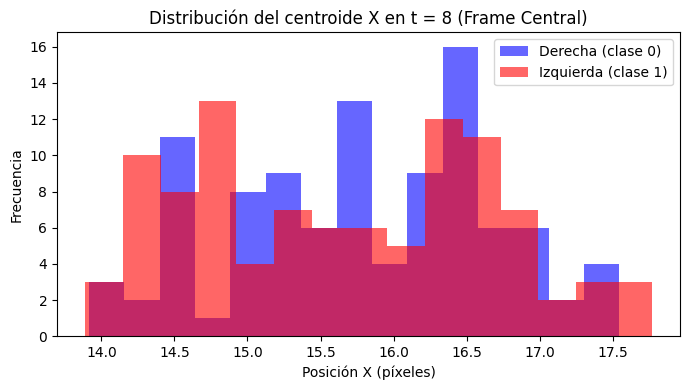

In [5]:
#posición horizontal de la pelota en t = 8
def centroide_x(frame):                      # frame: (1, H, W)
    f = frame[0]; xs = torch.arange(f.shape[1]).float()
    return float((f.sum(0) * xs).sum() / (f.sum() + 1e-8))

# 1) Toma 100 videos de derecha (clase 0) y 100 de izquierda (clase 1)
indices_der = (Y_ent == 0).nonzero().flatten()[:100]
indices_izq = (Y_ent == 1).nonzero().flatten()[:100]

# 2) Calcula centroide_x(video[8]) en cada uno
cx_derecha = [centroide_x(X_ent[i, 8]) for i in indices_der]
cx_izquierda = [centroide_x(X_ent[i, 8]) for i in indices_izq]

# 3) Dibuja los dos histogramas superpuestos
plt.figure(figsize=(7, 4))
plt.hist(cx_derecha, bins=15, alpha=0.6, label="Derecha (clase 0)", color="blue")
plt.hist(cx_izquierda, bins=15, alpha=0.6, label="Izquierda (clase 1)", color="red")
plt.title("Distribución del centroide X en t = 8 (Frame Central)")
plt.xlabel("Posición X (píxeles)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

¿Cuántos parámetros añade la LSTM respecto a la CNN estática? ¿Qué porcentaje del total representa? Con ese dato, ¿es la LSTM la parte "cara" del modelo?

In [19]:
# Fórmula: 4 compuertas * (W_ih + W_hh + b_ih + b_hh)

dim = 64
oculto = 64
p_lstm = 4 * (dim*oculto + oculto*oculto + 2*oculto)
p_cnn  = 40358
p_total = 73638
print(f"LSTM params (fórmula): {p_lstm:,}") #si es 33,280 coincide con la salida del laboratorio
print(f"LSTM = {100*p_lstm/p_total:.1f}% del total")
print(f"CNN  = {100*p_cnn/p_total:.1f}% del total")

LSTM params (fórmula): 33,280
LSTM = 45.2% del total
CNN  = 54.8% del total


**¿Es la parte "cara" del modelo? En parámetros, no la CNN aporta el 54.8 %, pero la LSTM sí domina el cómputo secuencial (no puede paralelizarse sobre T).**

---
# PARTE C
Entrenamiento y comparación

La CNN estática se entrena con **todos los frames** (cada uno etiquetado con la acción de su video), y la CNN-LSTM con videos completos. Así ambos modelos ven **la misma cantidad de imágenes** por época. Se evalúan dos variantes de la estática: con **un solo frame** (el central) y con **voto de los 16 frames**.

In [7]:
EPOCAS, LOTE, LR = 8, 32, 3e-3

def entrenar(tipo, paso_frames=1, epocas=EPOCAS, lr=LR, semilla=SEED, verbose=True):
    """paso_frames: 1 usa los T frames; 2 usa uno de cada dos; 4 usa uno de cada cuatro..."""
    fijar_semilla(semilla)
    Xe, Xv = X_ent[:, ::paso_frames], X_val[:, ::paso_frames]
    m = (CNNEstatica() if tipo == "estatica" else CNNLSTM()).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    dl = DataLoader(TensorDataset(Xe, Y_ent), batch_size=LOTE, shuffle=True)
    hist = []; t0 = time.perf_counter()
    for ep in range(epocas):
        m.train(); acum = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            if tipo == "estatica":
                lg = m(xb); l = F.cross_entropy(lg.flatten(0, 1), yb[:, None].expand(-1, xb.shape[1]).flatten())
            else:
                l = F.cross_entropy(m(xb), yb)
            l.backward(); opt.step(); acum += l.item() * len(xb)
        acc = evaluar(m, tipo, Xv, Y_val)["acc_video"]
        hist.append((acum / len(Xe), acc))
        if verbose and (ep % 2 == 1 or ep == epocas - 1):
            print(f"  [{tipo:8s} paso={paso_frames}] época {ep+1}/{epocas} · pérdida {hist[-1][0]:.4f} · exactitud val {acc:.3f}")
    r = evaluar(m, tipo, Xv, Y_val); r.update({"modelo": m, "hist": hist, "seg": time.perf_counter() - t0, "paso": paso_frames})
    return r

def evaluar(m, tipo, X, Y, lote=100):
    m.eval(); pred_video, pred_central = [], []
    with torch.no_grad():
        for i in range(0, len(X), lote):
            xb = X[i:i+lote].to(DEVICE)
            if tipo == "estatica":
                lg = m(xb)
                pred_video.append(F.softmax(lg, -1).mean(1).argmax(-1).cpu())      # voto de todos los frames
                pred_central.append(lg[:, xb.shape[1] // 2].argmax(-1).cpu())      # solo el frame central
            else:
                p = m(xb).argmax(-1).cpu(); pred_video.append(p); pred_central.append(p)
    pv, pc = torch.cat(pred_video), torch.cat(pred_central)
    cm = torch.bincount(Y * N_CLASES + pv, minlength=N_CLASES ** 2).reshape(N_CLASES, N_CLASES)
    return {"acc_video": float((pv == Y).float().mean()), "acc_central": float((pc == Y).float().mean()), "cm": cm}

RES = {}
RES["estatica"] = entrenar("estatica")
RES["cnn_lstm"] = entrenar("lstm")

  [estatica paso=1] época 2/8 · pérdida 1.3942 · exactitud val 0.537
  [estatica paso=1] época 4/8 · pérdida 1.3301 · exactitud val 0.527
  [estatica paso=1] época 6/8 · pérdida 1.3089 · exactitud val 0.500
  [estatica paso=1] época 8/8 · pérdida 1.2904 · exactitud val 0.473
  [lstm     paso=1] época 2/8 · pérdida 0.0916 · exactitud val 1.000
  [lstm     paso=1] época 4/8 · pérdida 0.0034 · exactitud val 1.000
  [lstm     paso=1] época 6/8 · pérdida 0.0016 · exactitud val 1.000
  [lstm     paso=1] época 8/8 · pérdida 0.0011 · exactitud val 1.000


,exactitud,parámetros,segundos
modelo,,,
CNN estática · 1 frame (central),0.257,40358,6.967
CNN estática · voto de 16 frames,0.473,40358,6.967
CNN-LSTM · 16 frames en orden,1.000,73638,4.655


Azar con 6 clases: 0.167


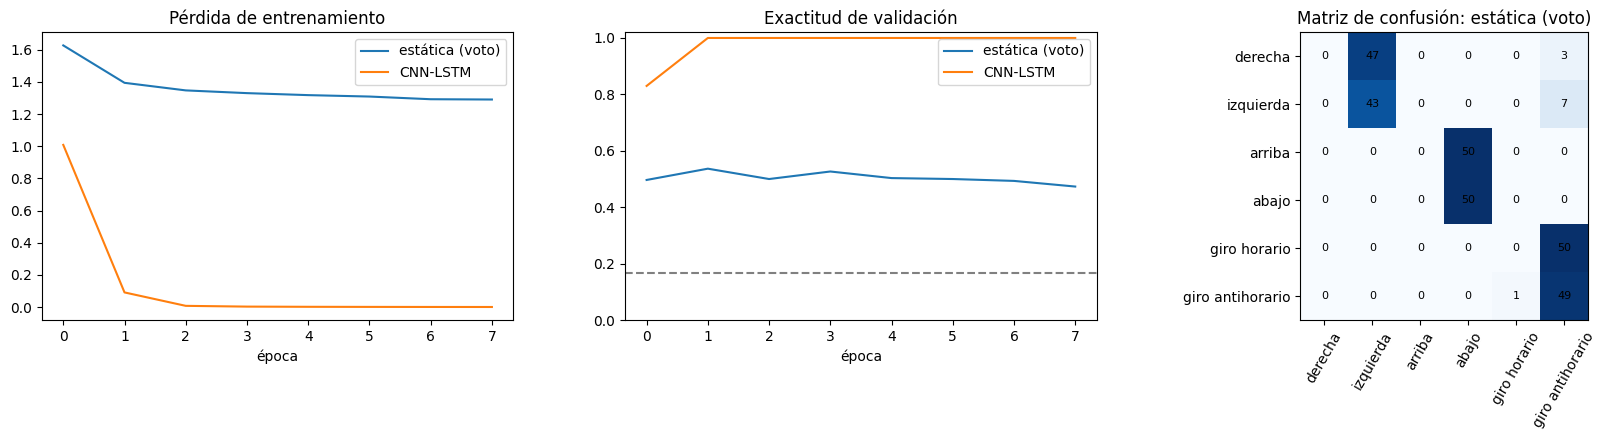

In [8]:
tabla = pd.DataFrame([
    {"modelo": "CNN estática · 1 frame (central)", "exactitud": RES["estatica"]["acc_central"], "parámetros": n_parametros(RES["estatica"]["modelo"]), "segundos": RES["estatica"]["seg"]},
    {"modelo": "CNN estática · voto de 16 frames", "exactitud": RES["estatica"]["acc_video"], "parámetros": n_parametros(RES["estatica"]["modelo"]), "segundos": RES["estatica"]["seg"]},
    {"modelo": "CNN-LSTM · 16 frames en orden", "exactitud": RES["cnn_lstm"]["acc_video"], "parámetros": n_parametros(RES["cnn_lstm"]["modelo"]), "segundos": RES["cnn_lstm"]["seg"]},
]).set_index("modelo").round(3)
display(tabla)
print(f"Azar con {N_CLASES} clases: {1/N_CLASES:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, nombre in [("estatica", "estática (voto)"), ("cnn_lstm", "CNN-LSTM")]:
    h = np.array(RES[k]["hist"]); ax[0].plot(h[:, 0], label=nombre); ax[1].plot(h[:, 1], label=nombre)
ax[0].set(title="Pérdida de entrenamiento", xlabel="época"); ax[0].legend()
ax[1].set(title="Exactitud de validación", xlabel="época", ylim=(0, 1.02)); ax[1].axhline(1/N_CLASES, ls="--", c="gray"); ax[1].legend()
for a, k, t in [(ax[2], "estatica", "Matriz de confusión: estática (voto)")]:
    cm = RES[k]["cm"].numpy(); a.imshow(cm, cmap="Blues"); a.set_title(t)
    a.set_xticks(range(N_CLASES)); a.set_xticklabels(ACCIONES, rotation=60); a.set_yticks(range(N_CLASES)); a.set_yticklabels(ACCIONES)
    for i in range(N_CLASES):
        for j in range(N_CLASES): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

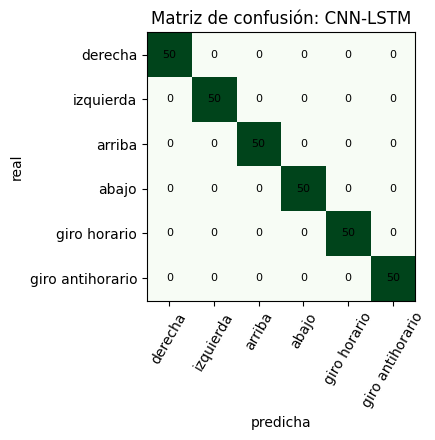

In [9]:
cm = RES["cnn_lstm"]["cm"].numpy()
plt.figure(figsize=(5.5, 4.5)); plt.imshow(cm, cmap="Greens"); plt.title("Matriz de confusión: CNN-LSTM")
plt.xticks(range(N_CLASES), ACCIONES, rotation=60); plt.yticks(range(N_CLASES), ACCIONES)
for i in range(N_CLASES):
    for j in range(N_CLASES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xlabel("predicha"); plt.ylabel("real"); plt.tight_layout(); plt.show()

**P-C1.** Con la tabla y las matrices de confusión: ¿qué exactitud obtuvo cada modelo? ¿Qué pares de acciones confunde la CNN estática y cuáles distingue sin problema?

**Modelo	Exactitud
CNN estática · 1 frame (central)	0.257
CNN estática · voto 16 frames	0.473
CNN-LSTM · 16 frames en orden	1.000
Azar (6 clases)	0.167**

**La CNN estática confunde los pares "opuestos": derecha ↔ izquierda, arriba ↔ abajo, giro horario ↔ giro antihorario.\
No confunde trayectorias con forma distinta: nunca mezcla una acción lineal (derecha/izquierda) con una circular (giro), ni una horizontal con una vertical es decir, distingue bien "qué trayectoria" pero no "en qué sentido".**

**A comparacion la diagonal de la matriz de la LSTM es perfecta 50/50 en cada clase de validación.**

**P-C2.** Compara la exactitud de **un solo frame** con la del **voto de 16 frames**. El voto mejora, pero tiene un techo. ¿Cuál es ese techo con 6 clases en tres parejas indistinguibles (derecha/izquierda, arriba/abajo, horario/antihorario) y por qué? Explica por qué promediar probabilidades de frames es una operación **invariante al orden** y qué tipo de información no puede recuperar.

- **Con 6 clases en 3 pares indistinguibles por frame, un clasificador que solo ve un frame asigna 50/50 dentro de cada par → la exactitud máxima teórica es 50 %.**
- **Votar 16 frames no cambia nada si cada frame tiene la misma ambigüedad, el promedio sigue siendo ~50/50 → el techo sigue siendo 50 %.**

**Por qué es invariante al orden, ya que es una suma conmutativa permutar los frames deja *p* idéntica y en el clasificador no puede distinguir "la pelota apareció primero a la izquierda y luego a la derecha" de lo contrario.**

**Qué información se pierde el orden temporal, velocidad (Δx/Δt) y sentido de giro todo lo que depende de la secuencia, no del conjunto de frames.**

---
# PARTE D
Costo computacional en secuencias

Una CNN-LSTM procesa $T$ frames: el costo de la CNN crece **linealmente** con $T$; además, la LSTM es **secuencial** (el paso $t$ necesita el estado del paso $t-1$) y la retropropagación en el tiempo guarda los estados de **todos** los pasos. Medimos cuatro cosas: operaciones (MACs), tiempo, memoria y exactitud, variando el número de frames.

## D.1 Operaciones por video (MACs)
Una *MAC* es una multiplicación seguida de una suma. Contamos las de las capas `Conv2d` y `Linear` con *hooks* y las de la LSTM con la fórmula $T\cdot 4\,h\,(d+h)$.

In [10]:
def contar_macs_cnn(cnn):
    total = {"macs": 0}
    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            total["macs"] += out.numel() // out.shape[0] * mod.in_channels * mod.kernel_size[0] * mod.kernel_size[1] // mod.groups
        elif isinstance(mod, nn.Linear):
            total["macs"] += mod.in_features * mod.out_features
    hs = [m.register_forward_hook(hook) for m in cnn.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    cnn.eval()
    with torch.no_grad(): cnn(torch.zeros(1, 1, TAM, TAM))
    for h in hs: h.remove()
    return total["macs"]

macs_frame = contar_macs_cnn(CodificadorCNN())
print(f"MACs de la CNN por frame: {macs_frame:,}")

def macs_video(n_frames, dim=64, oculto=64):
    cnn = n_frames * macs_frame
    lstm_ = n_frames * 4 * oculto * (dim + oculto)
    return cnn, lstm_

filas = []
for n in [1, 2, 4, 8, 16, 32, 64]:
    c, l = macs_video(n); filas.append({"frames T": n, "MACs CNN": c, "MACs LSTM": l, "total": c + l, "fracción LSTM": round(l / (c + l), 3)})
display(pd.DataFrame(filas).set_index("frames T"))

MACs de la CNN por frame: 2,523,136


,MACs CNN,MACs LSTM,total,fracción LSTM
frames T,,,,
1,2523136,32768,2555904,0.013
2,5046272,65536,5111808,0.013
4,10092544,131072,10223616,0.013
8,20185088,262144,20447232,0.013
16,40370176,524288,40894464,0.013
32,80740352,1048576,81788928,0.013
64,161480704,2097152,163577856,0.013


Grafica el total de MACs contra $T$ en escala lineal. Confirma que es una recta. Después calcula cuántos MACs tendría un video de 10 s a 30 fps (300 frames) con esta misma red, y cuántos con una CNN de 4 GMACs por frame (similar a una ResNet-50 a 224×224).

,MACs CNN,MACs LSTM,total,fracción LSTM
frames T,,,,
1,2523136,32768,2555904,0.0128
2,5046272,65536,5111808,0.0128
4,10092544,131072,10223616,0.0128
8,20185088,262144,20447232,0.0128
16,40370176,524288,40894464,0.0128
32,80740352,1048576,81788928,0.0128
64,161480704,2097152,163577856,0.0128


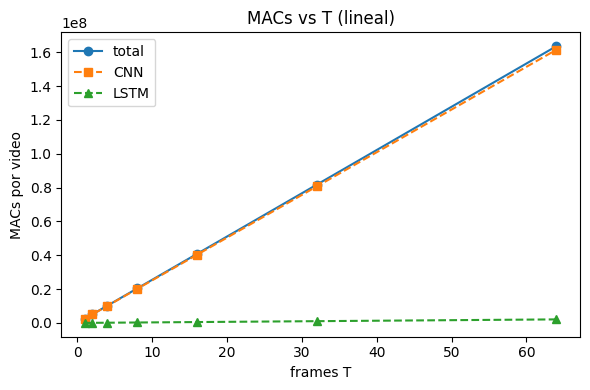


10 s a 30 fps = 300 frames (esta red)
CNN = 0.757 GMACs · LSTM = 0.010 GMACs · total = 0.767 GMACs

300 frames (CNN 4 GMACs/frame) similar a una ResNet-50 
CNN = 1.20 TMACs — LSTM sigue siendo 0.010 GMACs (despreciable)


In [23]:
#completado
filas = []
for n in [1, 2, 4, 8, 16, 32, 64]:
    c, l = macs_video(n)
    filas.append({"frames T": n, "MACs CNN": c, "MACs LSTM": l,
                  "total": c + l, "fracción LSTM": round(l / (c + l), 4)})
df_macs = pd.DataFrame(filas).set_index("frames T")
display(df_macs)

plt.figure(figsize=(6, 4))
plt.plot(df_macs.index, df_macs["total"], "o-", label="total")
plt.plot(df_macs.index, df_macs["MACs CNN"], "s--", label="CNN")
plt.plot(df_macs.index, df_macs["MACs LSTM"], "^--", label="LSTM")
plt.xlabel("frames T"); plt.ylabel("MACs por video"); plt.legend()
plt.title("MACs vs T (lineal)"); plt.tight_layout(); plt.show()

# 10 s a 30 fps = 300 frames
T300 = 300
c300, l300 = macs_video(T300)
print(f"\n10 s a 30 fps = 300 frames (esta red)")
print(f"CNN = {c300/1e9:.3f} GMACs · LSTM = {l300/1e9:.3f} GMACs · total = {(c300+l300)/1e9:.3f} GMACs")

# Con CNN pesada ~4 GMACs/frame (≈ ResNet-50 @ 224×224)
G = 4e9
c_big = T300 * G
print(f"\n300 frames (CNN 4 GMACs/frame) similar a una ResNet-50 ")
print(f"CNN = {c_big/1e12:.2f} TMACs — LSTM sigue siendo {l300/1e9:.3f} GMACs (despreciable)")

¿Qué parte del costo domina en este modelo: la CNN o la LSTM? ¿Cambiaría la respuesta con una CNN mucho más grande? Explica qué estrategias reducen el costo de un video (submuestrear frames, reducir resolución, CNN ligera).

- **La CNN domina el cómputo la fracción de LSTM es ~1.3 % del total (constante con T).**

- **Con una ResNet-50 como extractor, la LSTM pasa a ser < 0.001 % seria completamente despreciable.**

- **Unas estrategias para reducir seria submuestrear T (T=8 → mitad), reducir resolución (32→16 = 1/4), o una CNN más ligera (menos canales o depthwise separable).**

## D.2 Tiempo y memoria al crecer T

,ms por paso de entrenamiento,memoria (MB)
frames T,,
2,4.4,40.2
4,5.4,53.5
8,4.4,82.1
16,6.1,139.2
32,12.1,253.5
64,29.2,763.1


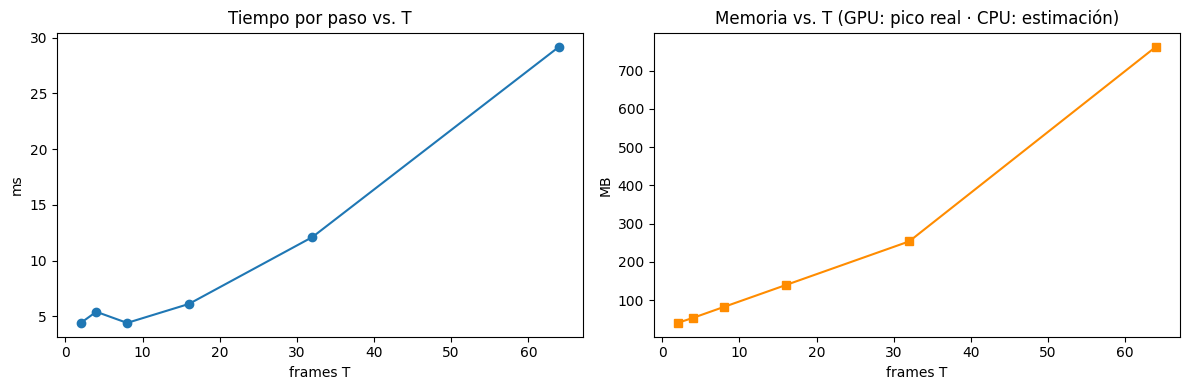

In [12]:
def medir_costo(T_prueba, lote=16, repeticiones=3):
    m = CNNLSTM().to(DEVICE); opt = torch.optim.Adam(m.parameters())
    x = torch.rand(lote, T_prueba, 1, TAM, TAM, device=DEVICE); y = torch.randint(0, N_CLASES, (lote,), device=DEVICE)
    def paso():
        opt.zero_grad(); F.cross_entropy(m(x), y).backward(); opt.step()
    paso()                                     # calentamiento
    if DEVICE == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for _ in range(repeticiones): paso()
    if DEVICE == "cuda": torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / repeticiones * 1000
    # memoria: en GPU el pico real; en CPU, el tamaño de la entrada + activaciones estimadas de la CNN
    if DEVICE == "cuda":
        mem = torch.cuda.max_memory_allocated() / 1e6
    else:
        mem = (x.numel() + lote * T_prueba * (16 * 32 * 32 + 32 * 16 * 16 + 64 * 8 * 8) * 2) * 4 / 1e6
    return ms, mem

filas = []
for n in [2, 4, 8, 16, 32, 64]:
    ms, mem = medir_costo(n); filas.append({"frames T": n, "ms por paso de entrenamiento": round(ms, 1), "memoria (MB)": round(mem, 1)})
costo = pd.DataFrame(filas).set_index("frames T"); display(costo)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(costo.index, costo.iloc[:, 0], "o-"); ax[0].set(title="Tiempo por paso vs. T", xlabel="frames T", ylabel="ms")
ax[1].plot(costo.index, costo.iloc[:, 1], "s-", c="darkorange"); ax[1].set(title="Memoria vs. T (GPU: pico real · CPU: estimación)", xlabel="frames T", ylabel="MB")
plt.tight_layout(); plt.show()

Ajusta una recta (`np.polyfit`) a "ms vs. T" y reporta la pendiente (ms por frame adicional). ¿Con cuántos frames tardaría un paso 1 segundo?

In [24]:
# completar
T_vals = np.array(costo.index, dtype=float)
ms_vals = costo.iloc[:, 0].values
pendiente, intercepto = np.polyfit(T_vals, ms_vals, 1)
print(f"ms(T) ≈ {pendiente:.3f}·T + {intercepto:.2f}")
print(f"Pendiente: {pendiente:.3f} ms/frame adicional")

T_1s = (1000 - intercepto) / pendiente
print(f"Para 1 s por paso: T ≈ {T_1s:.0f} frames")

ms(T) ≈ 0.400·T + 1.87
Pendiente: 0.400 ms/frame adicional
Para 1 s por paso: T ≈ 2495 frames


¿El tiempo crece de forma lineal con $T$? Explica por qué la LSTM no se puede paralelizar a lo largo del tiempo y la CNN sí lo hace (los $B\cdot T$ frames se procesan juntos).

- **Es casi lineal hay un overhead base que aplana el arranque y a partir de T≈64 empieza a notarse la presión de memoria (mayor pendiente aparente) y la memoria sí crece casi linealmente con T porque BPTT guarda todos los h_t intermedios.**

- **Por qué la LSTM no se paraleliza a lo largo de T:
La ecuación es $h_t=f(h_{t-1},x_t)$ dentro del texto.\
Dependencia estricta entre pasos h_5 no se puede calcular sin h_4 y la GPU solo puede lanzar todos los h_t si conoce todos los h_{t-1}, lo que no ocurre hasta terminado el paso anterior.**

- **Por qué la CNN sí procesa los B·T frames independientemente, se debe a que el forward de la CNN ve (B·T, C, H, W) y todos los frames pasan en paralelo por las convoluciones siendo esta la diferencia fundamental CNN = paralela sobre T · LSTM = serial sobre T.**

## D.3 ¿Cuántos frames necesita la CNN-LSTM? (submuestreo temporal)

,exactitud,MACs por video,segundos de entrenamiento
frames usados,,,
16,1.000,40894464,4.7
8,1.000,20447232,2.5
4,1.000,10223616,1.7
2,0.877,5111808,1.5


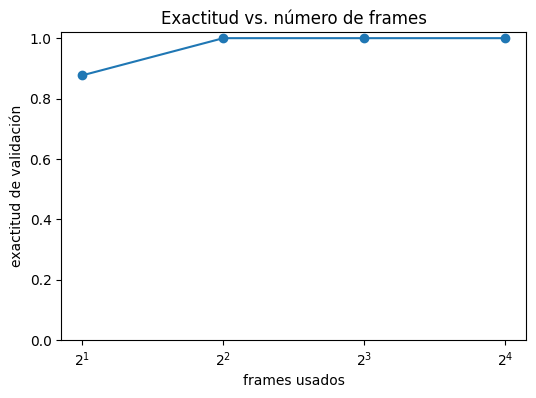

In [14]:
for paso in [2, 4, 8]:
    RES[f"lstm_paso{paso}"] = entrenar("lstm", paso_frames=paso, verbose=False)

filas = []
for paso in [1, 2, 4, 8]:
    r = RES["cnn_lstm"] if paso == 1 else RES[f"lstm_paso{paso}"]
    n = T // paso; c, l = macs_video(n)
    filas.append({"frames usados": n, "exactitud": round(r["acc_video"], 3), "MACs por video": c + l, "segundos de entrenamiento": round(r["seg"], 1)})
sub = pd.DataFrame(filas).set_index("frames usados"); display(sub)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sub.index, sub["exactitud"], "o-"); ax.set_xscale("log", base=2); ax.set(xlabel="frames usados", ylabel="exactitud de validación", title="Exactitud vs. número de frames", ylim=(0, 1.02))
plt.show()

¿Cuántos frames mínimos necesita la CNN-LSTM para igualar su exactitud con 16? ¿Cuánto cómputo (MACs) ahorra? Con tu tabla, propón el valor de $T$ que elegirías para desplegar el modelo y justifica el balance exactitud–costo.

In [25]:
# completar
filas = []
for paso in [1, 2, 4, 8]:
    r = RES["cnn_lstm"] if paso == 1 else RES[f"lstm_paso{paso}"]
    n = T // paso
    c, l = macs_video(n)
    filas.append({"frames usados": n, "exactitud": round(r["acc_video"], 3),
                  "MACs por video": c + l, "segundos": round(r["seg"], 1)})
sub = pd.DataFrame(filas).set_index("frames usados"); display(sub)

# Elección de T para desplegar: T = 8 — precisión máxima con la mitad del cómputo

,exactitud,MACs por video,segundos
frames usados,,,
16,1.000,40894464,4.7
8,1.000,20447232,2.5
4,1.000,10223616,1.7
2,0.877,5111808,1.5


 Con solo 2 frames, ¿qué información mínima permite distinguir `derecha` de `izquierda`? ¿Y `giro horario` de `giro antihorario`? ¿Cuál de las dos parejas necesita más frames y por qué?

- **derecha vs izquierda: confirma sí x_2 - x_1 revela el sentido (positivo = derecha).**

- **giro horario vs antihorario es un poco ambiguo por que son dos puntos sobre una circunferencia solo definen la cuerda; si los frames caen casi opuestos o casi idénticos en fase, el sentido de giro es indeterminable.**

- **El giro necesita más frames porque la información está en la curvatura (segunda derivada), no en un solo par de posiciones. En cambio, las 4 acciones lineales solo necesitan la dirección (primera derivada) → 2 frames bastan.**